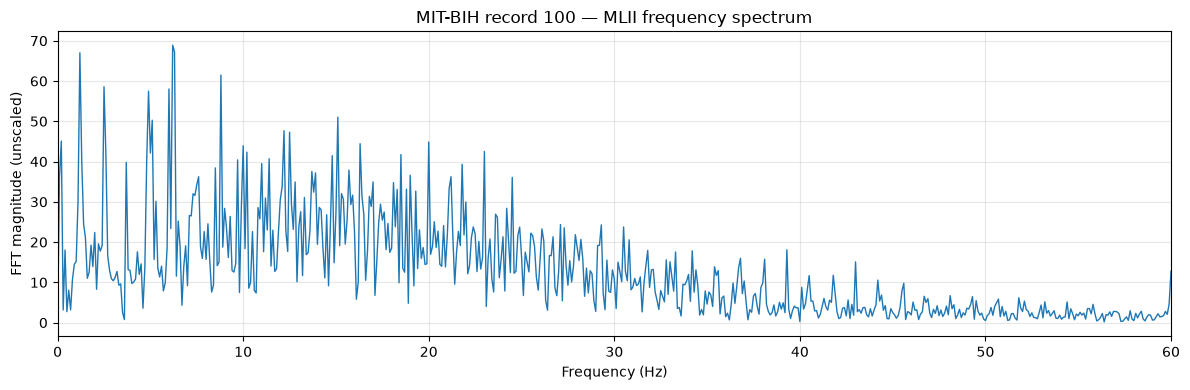

Frequency spacing: 0.10 Hz


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import wfdb

record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb/1.0.0",
    sampto=3600,
    channels=[0],
)

ecg = record.p_signal[:, 0]
fs = record.fs

centered_ecg = ecg - ecg.mean()
fft_values = np.fft.rfft(centered_ecg)
frequencies = np.fft.rfftfreq(len(centered_ecg), d=1 / fs)
fft_magnitude = np.abs(fft_values)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(frequencies, fft_magnitude, linewidth=1)
ax.set_title("MIT-BIH record 100 — MLII frequency spectrum")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.set_xlim(0, 60)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Frequency spacing: {frequencies[1] - frequencies[0]:.2f} Hz")

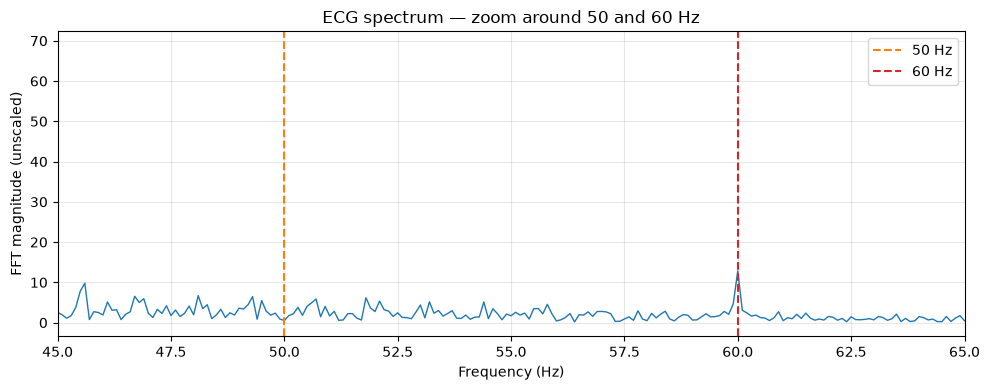

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequencies, fft_magnitude, linewidth=1)

ax.set_xlim(45, 65)
ax.axvline(50, color="tab:orange", linestyle="--", label="50 Hz")
ax.axvline(60, color="tab:red", linestyle="--", label="60 Hz")

ax.set_title("ECG spectrum — zoom around 50 and 60 Hz")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

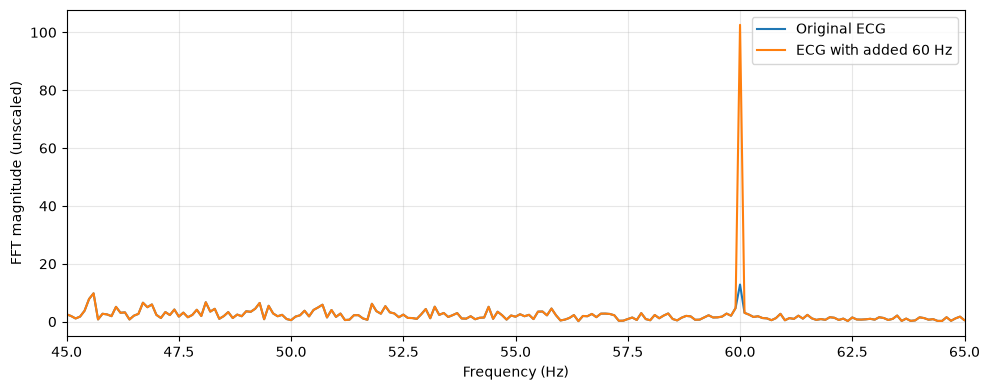

In [3]:
time_seconds = np.arange(len(ecg)) / fs
interference = 0.05 * np.sin(2 * np.pi * 60 * time_seconds)
ecg_with_interference = ecg + interference

centered_modified = ecg_with_interference - ecg_with_interference.mean()
modified_magnitude = np.abs(np.fft.rfft(centered_modified))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequencies, fft_magnitude, label="Original ECG")
ax.plot(frequencies, modified_magnitude, label="ECG with added 60 Hz")
ax.set_xlim(45, 65)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

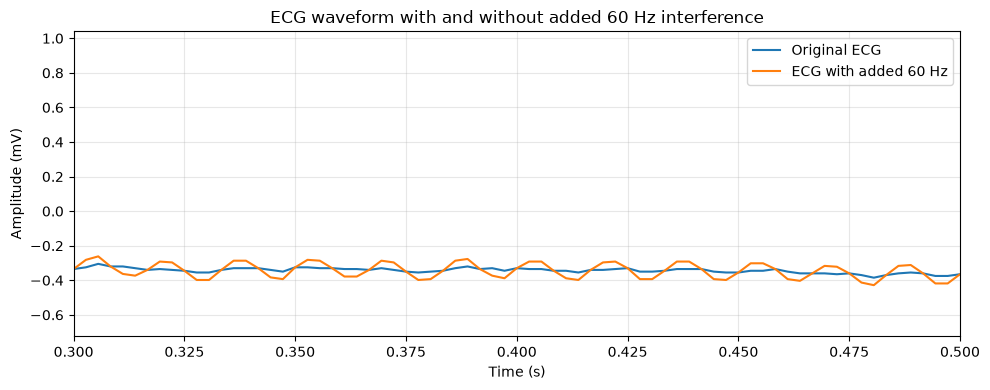

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(time_seconds, ecg, label="Original ECG")
ax.plot(time_seconds, ecg_with_interference, label="ECG with added 60 Hz")

ax.set_xlim(0.30, 0.50)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (mV)")
ax.set_title("ECG waveform with and without added 60 Hz interference")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

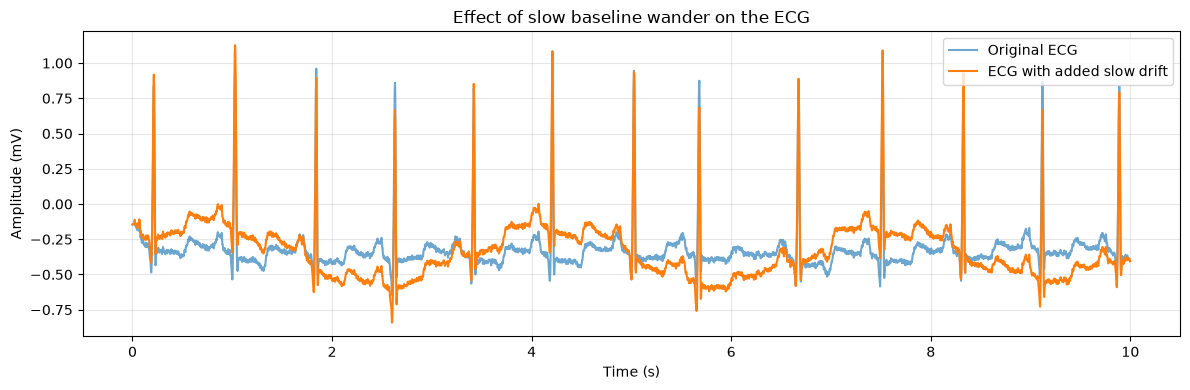

In [5]:
slow_drift = 0.2 * np.sin(2 * np.pi * 0.3 * time_seconds)
ecg_with_drift = ecg + slow_drift

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_seconds, ecg, label="Original ECG", alpha=0.65)
ax.plot(time_seconds, ecg_with_drift, label="ECG with added slow drift")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (mV)")
ax.set_title("Effect of slow baseline wander on the ECG")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

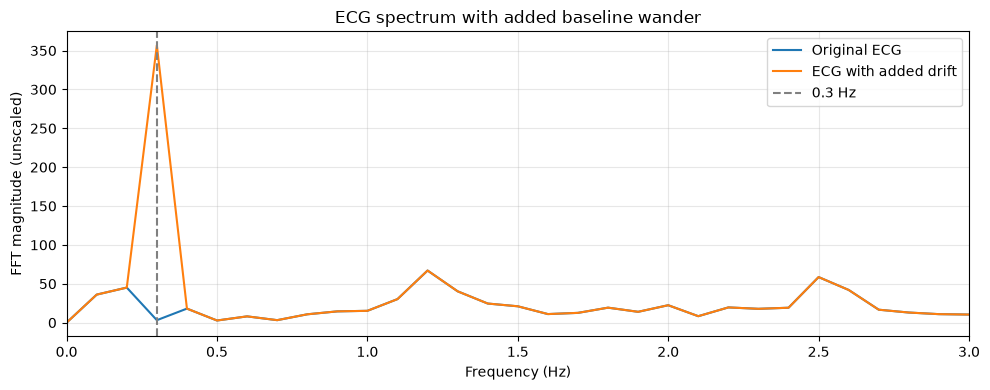

In [6]:
centered_drift_ecg = ecg_with_drift - ecg_with_drift.mean()
drift_magnitude = np.abs(np.fft.rfft(centered_drift_ecg))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequencies, fft_magnitude, label="Original ECG")
ax.plot(frequencies, drift_magnitude, label="ECG with added drift")
ax.axvline(0.3, color="gray", linestyle="--", label="0.3 Hz")
ax.set_xlim(0, 3)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.set_title("ECG spectrum with added baseline wander")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

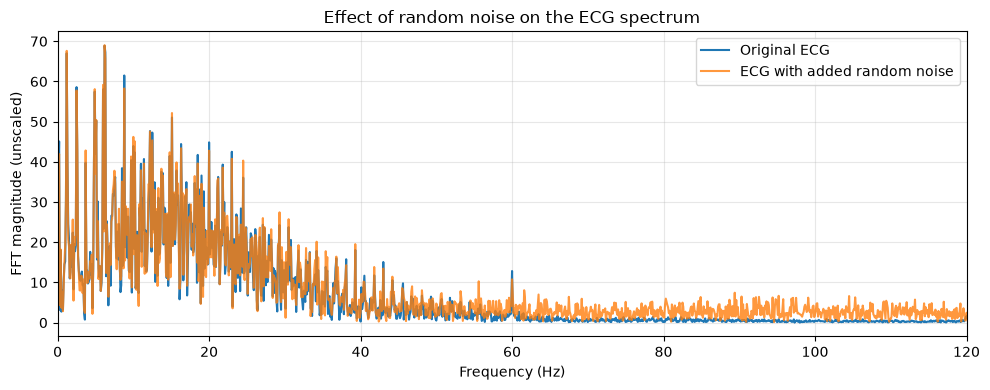

In [7]:
rng = np.random.default_rng(42)
random_noise = rng.normal(0, 0.05, size=len(ecg))
ecg_with_random_noise = ecg + random_noise

centered_noisy_ecg = ecg_with_random_noise - ecg_with_random_noise.mean()
noisy_magnitude = np.abs(np.fft.rfft(centered_noisy_ecg))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequencies, fft_magnitude, label="Original ECG")
ax.plot(frequencies, noisy_magnitude, label="ECG with added random noise", alpha=0.8)
ax.set_xlim(0, 120)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.set_title("Effect of random noise on the ECG spectrum")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

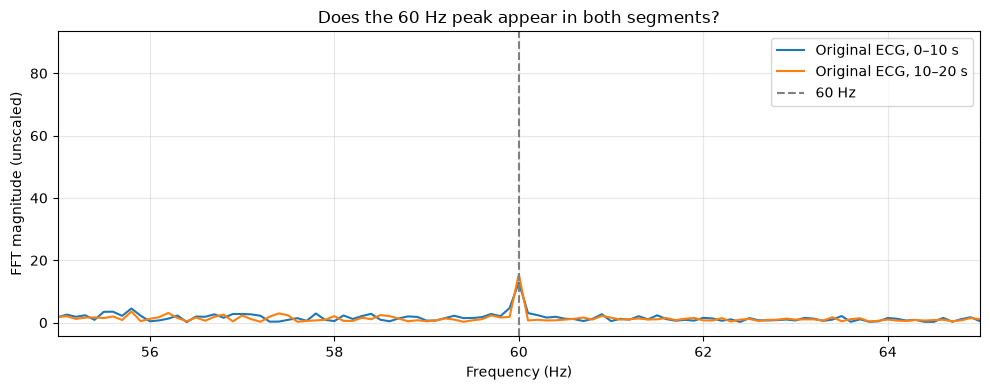

In [8]:
segment_samples = len(ecg)

next_record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb/1.0.0",
    sampfrom=segment_samples,
    sampto=2 * segment_samples,
    channels=[0],
)

next_ecg = next_record.p_signal[:, 0]
next_centered = next_ecg - next_ecg.mean()
next_magnitude = np.abs(np.fft.rfft(next_centered))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(frequencies, fft_magnitude, label="Original ECG, 0–10 s")
ax.plot(frequencies, next_magnitude, label="Original ECG, 10–20 s")
ax.axvline(60, color="gray", linestyle="--", label="60 Hz")
ax.set_xlim(55, 65)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (unscaled)")
ax.set_title("Does the 60 Hz peak appear in both segments?")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Filtering requirements

- **Slow drift:** Reduce the added 0.3 Hz drift. Check whether the filtered trace follows the original ECG more closely between beats.
- **60 Hz component:** Reduce the narrow peak at 60 Hz. Check its height before and after filtering.
- **Random noise:** Compare how much of the rapid variation still remains. Added random noise spreads across many frequencies.
- **Beat shape and timing:** Zoom in on a few beats and check whether their sharp peaks keep a similar shape and occur at the same times.

Use the original ECG as a comparison when testing signals we modified ourselves. The original recording already contains a small 60 Hz peak.